In [44]:
import pandas as pd
import math

# =========================
# PATHS
# =========================
MATCH_CSV = "data_processed/match_master_clean_mergedwithclimate_teamnormalized.csv"
OUT_ELO_CSV = "data_processed/team_elo_history.csv"

# =========================
# BASE PARAMETERS
# =========================
INITIAL_ELO = 1500

# Dynamic K
K_BASE = 40
K_MIN = 10
K_CONFIDENCE_C = 20

# Confidence (ranking)
CONFIDENCE_C = 25

# Inactivity penalties
INACTIVITY_1 = 365
INACTIVITY_2 = 730
PENALTY_1 = 50
PENALTY_2 = 100

# League-specific half-life (days)
HALF_LIFE_MAP = {
    "International": 450,
    "IPL": 240,
    "BBL": 240,
    "PSL": 240,
    "BPL": 240,
    "CPL": 240,
    "SA20": 240,
    "ILT20": 240,
    "MLC": 240,
    "SMAT": 300,
    "Domestic": 300,
}
DEFAULT_HALF_LIFE = 240

# =========================
# LOAD DATA
# =========================
df = pd.read_csv(MATCH_CSV)
df["match_id"] = df["match_id"].astype(str)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values("date")

# =========================
# STORAGE
# =========================
elo = {}
last_played = {}
matches_played = {}
history = []

# =========================
# HELPERS
# =========================
def expected_score(r_a, r_b):
    return 1 / (1 + 10 ** ((r_b - r_a) / 400))

def get_half_life(league):
    return HALF_LIFE_MAP.get(league, DEFAULT_HALF_LIFE)

def apply_time_decay(team, current_date, league):
    if team not in last_played:
        return elo[team]

    days = (current_date - last_played[team]).days
    if days <= 0:
        return elo[team]

    h = get_half_life(league)
    decay = math.exp(-math.log(2) * days / h)
    return INITIAL_ELO + (elo[team] - INITIAL_ELO) * decay

def apply_inactivity_penalty(team, current_date):
    if team not in last_played:
        return elo[team]

    days = (current_date - last_played[team]).days
    penalty = 0
    if days > INACTIVITY_1:
        penalty += PENALTY_1
    if days > INACTIVITY_2:
        penalty += PENALTY_2
    return elo[team] - penalty

def dynamic_k(mp):
    k = K_BASE / math.sqrt(1 + mp / K_CONFIDENCE_C)
    return max(k, K_MIN)

def confidence(team):
    mp = matches_played.get(team, 0)
    return 1 - math.exp(-mp / CONFIDENCE_C)

# =========================
# RPW-BASED MOV
# =========================
def rpw(team, row):
    if team == row["team1"]:
        runs = row["first_innings_score"]
        wkts = row["first_wp"] + row["first_wm"] + row["first_wd"]
    else:
        runs = row["second_innings_score"]
        wkts = row["second_wp"] + row["second_wm"] + row["second_wd"]

    if pd.isna(runs):
        return None

    return runs / (wkts + 1)

def mov_multiplier_rpw(row):
    winner = row["winner"]
    if winner not in (row["team1"], row["team2"]):
        return 1.0

    loser = row["team2"] if winner == row["team1"] else row["team1"]

    rpw_w = rpw(winner, row)
    rpw_l = rpw(loser, row)

    if rpw_w is None or rpw_l is None or rpw_l <= 0:
        return 1.0

    dominance = rpw_w / rpw_l
    return math.log(1 + dominance)

# =========================
# MAIN LOOP
# =========================
for _, row in df.iterrows():
    team_a = row["team1"]
    team_b = row["team2"]
    winner = row["winner"]
    league = row["league"]
    match_date = row["date"]

    if pd.isna(winner) or pd.isna(match_date):
        continue

    # Init
    elo.setdefault(team_a, INITIAL_ELO)
    elo.setdefault(team_b, INITIAL_ELO)
    matches_played.setdefault(team_a, 0)
    matches_played.setdefault(team_b, 0)

    # Apply decay + inactivity
    elo[team_a] = apply_time_decay(team_a, match_date, league)
    elo[team_b] = apply_time_decay(team_b, match_date, league)

    elo[team_a] = apply_inactivity_penalty(team_a, match_date)
    elo[team_b] = apply_inactivity_penalty(team_b, match_date)

    r_a = elo[team_a]
    r_b = elo[team_b]

    exp_a = expected_score(r_a, r_b)
    exp_b = 1 - exp_a

    if winner == team_a:
        s_a, s_b = 1, 0
    elif winner == team_b:
        s_a, s_b = 0, 1
    else:
        continue

    mov = mov_multiplier_rpw(row)

    k_a = dynamic_k(matches_played[team_a])
    k_b = dynamic_k(matches_played[team_b])

    # === STORE TRUE PRE-UPDATE RATINGS ===
    elo_before_a = elo[team_a]
    elo_before_b = elo[team_b]

    # === UPDATE ===
    elo[team_a] += k_a * mov * (s_a - exp_a)
    elo[team_b] += k_b * mov * (s_b - exp_b)

    # === TRUE MATCH DELTA ===
    delta_a = elo[team_a] - elo_before_a
    delta_b = elo[team_b] - elo_before_b

    matches_played[team_a] += 1
    matches_played[team_b] += 1
    last_played[team_a] = match_date
    last_played[team_b] = match_date

    history.append({
        "match_id": row["match_id"],
        "date": match_date,
        "league": league,
        "team": team_a,
        "opponent": team_b,
        "elo_after": elo[team_a],
        "elo_delta": delta_a,
        "confidence": confidence(team_a),
        "effective_elo": 1500 + (elo[team_a] - 1500) * confidence(team_a),
        "matches_played": matches_played[team_a],
        "result": "win" if winner == team_a else "loss"
    })
    
    history.append({
        "match_id": row["match_id"],
        "date": match_date,
        "league": league,
        "team": team_b,
        "opponent": team_a,
        "elo_after": elo[team_b],
        "elo_delta": delta_b,
        "confidence": confidence(team_b),
        "effective_elo": 1500 + (elo[team_b] - 1500) * confidence(team_b),
        "matches_played": matches_played[team_b],
        "result": "win" if winner == team_b else "loss"
    })

# =========================
# SAVE
# =========================
elo_df = pd.DataFrame(history)
elo_df.to_csv(OUT_ELO_CSV, index=False)

# =========================
# FINAL RANKINGS
# =========================
final_rank = (
    elo_df.sort_values("date")
    .groupby("team")
    .tail(1)
    .sort_values("effective_elo", ascending=False)
)

print("Saved:", OUT_ELO_CSV)
print("\nTop 10 teams (Effective Elo):")
print(final_rank[["team", "elo_after", "confidence", "effective_elo", "matches_played"]].head(10))


Saved: data_processed/team_elo_history.csv

Top 10 teams (Effective Elo):
                   team    elo_after  confidence  effective_elo  \
11102             India  1615.190155    0.998744    1615.045502   
11132      Mi Cape Town  1602.149298    0.710616    1572.588903   
11129  Fortune Barishal  1570.047381    0.955843    1566.954287   
9450             Punjab  1573.625834    0.834701    1561.455565   
10542         Mi London  1580.615068    0.721963    1558.201072   
11709         Australia  1557.962359    0.991434    1557.465876   
11680          Somerset  1555.464583    0.998640    1555.389130   
11682            Surrey  1553.728303    0.998127    1553.627648   
11710       New Zealand  1551.690496    0.996151    1551.491551   
10649    St Lucia Kings  1560.561911    0.820934    1549.717323   

       matches_played  
11102             167  
11132              31  
11129              78  
9450               45  
10542              32  
11709             119  
11680             16

elo details of a team


Elo Summary — Royal Challengers Bengaluru
Highest Effective Elo : 1550.73
Date                 : 2016-05-24
Opponent             : Gujarat Lions
League               : IPL
-------------------------------------------------------
Lowest Effective Elo  : 1392.64
Date                 : 2019-04-07
Opponent             : Delhi Capitals
League               : IPL
-------------------------------------------------------
Latest Match
Date           : 2025-06-03
Opponent       : Punjab Kings
League         : IPL
Elo After      : 1536.59
Confidence     : 0.998
Effective Elo  : 1536.53
Matches Played : 159
Result         : win

Biggest Elo GAIN (True Match Impact)
-------------------------------------------------------
+34.02 Elo
Date     : 2015-04-26
Opponent : Delhi Capitals
League   : IPL
Result   : win

Biggest Elo LOSS (True Match Impact)
-------------------------------------------------------
-25.21 Elo
Date     : 2015-04-13
Opponent : Sunrisers Hyderabad
League   : IPL
Result   : loss


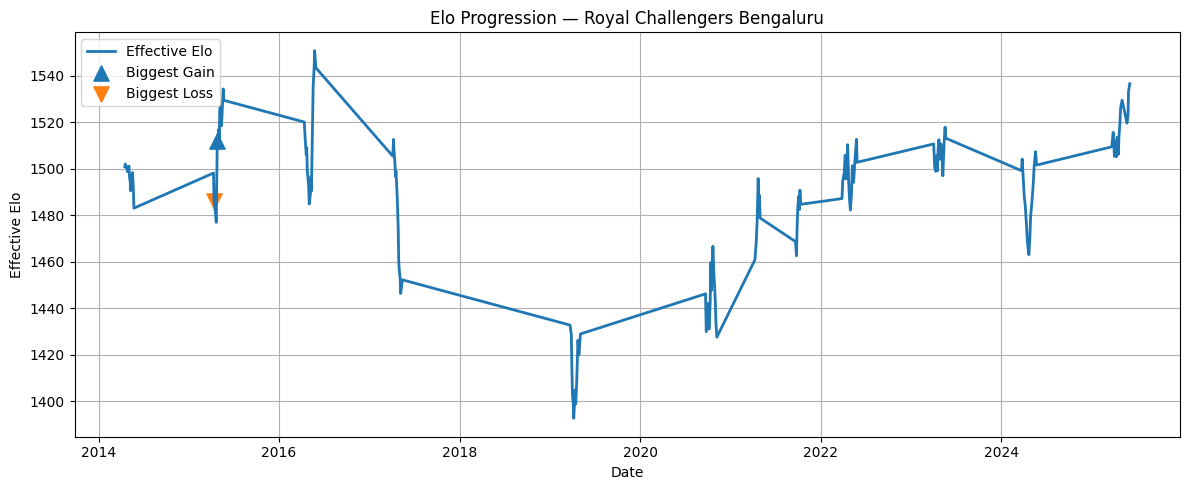

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

def analyze_team_elo(
    team_name,
    elo_csv="data_processed/team_elo_history.csv"
):
    df = pd.read_csv(elo_csv)
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    team_df = (
        df[df["team"] == team_name]
        .sort_values("date")
        .reset_index(drop=True)
    )

    if team_df.empty:
        print(f"No Elo data found for team: {team_name}")
        return

    # =========================
    # BASIC STATS
    # =========================
    high_idx = team_df["effective_elo"].idxmax()
    low_idx = team_df["effective_elo"].idxmin()
    latest = team_df.iloc[-1]

    print(f"\nElo Summary — {team_name}")
    print("=" * 55)

    print(
        f"Highest Effective Elo : {team_df.loc[high_idx, 'effective_elo']:.2f}\n"
        f"Date                 : {team_df.loc[high_idx, 'date'].date()}\n"
        f"Opponent             : {team_df.loc[high_idx, 'opponent']}\n"
        f"League               : {team_df.loc[high_idx, 'league']}"
    )

    print("-" * 55)

    print(
        f"Lowest Effective Elo  : {team_df.loc[low_idx, 'effective_elo']:.2f}\n"
        f"Date                 : {team_df.loc[low_idx, 'date'].date()}\n"
        f"Opponent             : {team_df.loc[low_idx, 'opponent']}\n"
        f"League               : {team_df.loc[low_idx, 'league']}"
    )

    print("-" * 55)

    print(
        f"Latest Match\n"
        f"Date           : {latest['date'].date()}\n"
        f"Opponent       : {latest['opponent']}\n"
        f"League         : {latest['league']}\n"
        f"Elo After      : {latest['elo_after']:.2f}\n"
        f"Confidence     : {latest['confidence']:.3f}\n"
        f"Effective Elo  : {latest['effective_elo']:.2f}\n"
        f"Matches Played : {latest['matches_played']}\n"
        f"Result         : {latest['result']}"
    )

    # =========================
    # TRUE MATCH IMPACT
    # =========================
    win_df = team_df[team_df["elo_delta"] > 0]
    loss_df = team_df[team_df["elo_delta"] < 0]

    if not win_df.empty:
        gain_idx = win_df["elo_delta"].idxmax()
        print("\nBiggest Elo GAIN (True Match Impact)")
        print("-" * 55)
        print(
            f"+{team_df.loc[gain_idx, 'elo_delta']:.2f} Elo\n"
            f"Date     : {team_df.loc[gain_idx, 'date'].date()}\n"
            f"Opponent : {team_df.loc[gain_idx, 'opponent']}\n"
            f"League   : {team_df.loc[gain_idx, 'league']}\n"
            f"Result   : {team_df.loc[gain_idx, 'result']}"
        )
    else:
        gain_idx = None
        print("\nNo wins available to compute biggest gain.")

    if not loss_df.empty:
        loss_idx = loss_df["elo_delta"].idxmin()
        print("\nBiggest Elo LOSS (True Match Impact)")
        print("-" * 55)
        print(
            f"{team_df.loc[loss_idx, 'elo_delta']:.2f} Elo\n"
            f"Date     : {team_df.loc[loss_idx, 'date'].date()}\n"
            f"Opponent : {team_df.loc[loss_idx, 'opponent']}\n"
            f"League   : {team_df.loc[loss_idx, 'league']}\n"
            f"Result   : {team_df.loc[loss_idx, 'result']}"
        )
    else:
        loss_idx = None
        print("\nNo losses available to compute biggest loss.")

    # =========================
    # PLOT (EFFECTIVE ELO)
    # =========================
    plt.figure(figsize=(12, 5))
    plt.plot(
        team_df["date"],
        team_df["effective_elo"],
        linewidth=2,
        label="Effective Elo"
    )

    if gain_idx is not None:
        plt.scatter(
            team_df.loc[gain_idx, "date"],
            team_df.loc[gain_idx, "effective_elo"],
            marker="^",
            s=120,
            label="Biggest Gain"
        )

    if loss_idx is not None:
        plt.scatter(
            team_df.loc[loss_idx, "date"],
            team_df.loc[loss_idx, "effective_elo"],
            marker="v",
            s=120,
            label="Biggest Loss"
        )

    plt.title(f"Elo Progression — {team_name}")
    plt.xlabel("Date")
    plt.ylabel("Effective Elo")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# =========================
# EXAMPLE
# =========================
analyze_team_elo("Royal Challengers Bengaluru")


elo ranking of a team in a league

In [46]:
import pandas as pd

def elo_ranking_by_league(
    league_name,
    elo_csv="data_processed/team_elo_history.csv",
    min_matches=5
):
    df = pd.read_csv(elo_csv)
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    league_df = df[df["league"] == league_name]

    if league_df.empty:
        print(f"No data found for league: {league_name}")
        return None

    # Latest record per team
    latest = (
        league_df.sort_values("date")
        .groupby("team")
        .tail(1)
        .reset_index(drop=True)
    )

    # Optional sanity filter (avoid 1–2 match noise)
    latest = latest[latest["matches_played"] >= min_matches]

    if latest.empty:
        print(f"No teams with >= {min_matches} matches in {league_name}")
        return None

    # Rank by EFFECTIVE elo
    latest = latest.sort_values("effective_elo", ascending=False).reset_index(drop=True)
    latest["rank"] = latest.index + 1

    return latest[
        [
            "rank",
            "team",
            "effective_elo",
            "elo_after",
            "confidence",
            "matches_played"
        ]
    ]


# =========================
# EXAMPLE
# =========================
elo_ranking_by_league("International")


,rank,team,effective_elo,elo_after,confidence,matches_played
0,1,India,1615.045502,1615.190155,0.998744,167
1,2,Australia,1557.465876,1557.962359,0.991434,119
2,3,New Zealand,1551.491551,1551.690496,0.996151,139
3,4,England,1524.374993,1524.499756,0.994908,132
4,5,Bangladesh,1487.576858,1487.445512,0.989538,114
5,6,Pakistan,1481.939530,1481.884685,0.996972,145
6,7,Sri Lanka,1475.828459,1475.619626,0.991434,119
7,8,South Africa,1475.579657,1475.407189,0.992987,124
8,9,Ireland,1442.900980,1433.539452,0.859142,49
9,10,West Indies,1440.855092,1440.617214,0.995994,138


In [40]:
import pandas as pd

# =========================
# INPUTS
# =========================
CSV_PATH = "data_processed/match_master_clean_mergedwithclimate_teamnormalized.csv"
TEAM_NAME = "Royal Challengers Bengaluru"  # <-- change this

# =========================
# LOAD DATA
# =========================
df = pd.read_csv(CSV_PATH)

# =========================
# ENSURE DATE TYPE
# =========================
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# =========================
# FILTER MATCHES OF TEAM
# =========================
team_matches = df[
    (df["team1"] == TEAM_NAME) | (df["team2"] == TEAM_NAME)
]

if team_matches.empty:
    print(f"No matches found for team: {TEAM_NAME}")
else:
    # =========================
    # GET LAST MATCH
    # =========================
    last_match = team_matches.sort_values("date").iloc[-1]

    print("Last match played by:", TEAM_NAME)
    print("----------------------------------")
    print("Match ID      :", last_match["match_id"])
    print("Date          :", last_match["date"].date())
    print("Team 1        :", last_match["team1"])
    print("Team 2        :", last_match["team2"])
    print("Winner        :", last_match.get("winner"))
    print("Victory Type  :", last_match.get("victory_type"))
    print("Victory Margin:", last_match.get("victory_margin"))
    print("Venue         :", last_match.get("venue"))
    print("City          :", last_match.get("city"))


Last match played by: Royal Challengers Bengaluru
----------------------------------
Match ID      : 1473511
Date          : 2025-06-03
Team 1        : Royal Challengers Bengaluru
Team 2        : Punjab Kings
Winner        : Royal Challengers Bengaluru
Victory Type  : runs
Victory Margin: 6.0
Venue         : Narendra Modi Stadium, Ahmedabad
City          : Ahmedabad
